> **Worked example (solved).** Read and run it alongside the D012 lesson; there is no separate key because this notebook is the key. The D012 assessment is the sentiment paper on the same reviews, which asks you to judge these methods rather than reproduce them.

# Case Study: Popchip Reviews Analysis

## Introduction
In this case study, we will analyse customer reviews for **Popchips**.
Our goal is to understand customer sentiment, identify key themes (flavors, issues), and classify reviews into actionable categories.

We will apply techniques from previous modules:
1.  **Preprocessing** (Cleaning Text)
2.  **EDA** (Rating Distributions)
3.  **Feature Extraction** (TF-IDF for keywords)
4.  **Sentiment Analysis** (Lexicon vs Deep Learning)
5.  **NER** (Extracting specific entities)
6.  **Zero-Shot Classification** (Categorising without training data)

## Dataset
The dataset is `Popchip_Reviews.xlsx`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# NLP Libraries
import nltk
from nltk.corpus import stopwords
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer

# Transformers
from transformers import pipeline

# Settings
sns.set_style("whitegrid")
%matplotlib inline

## 1. Data Loading and EDA

In [2]:
# Load the dataset
# Note: Ensure the path is correct relative to this notebook
file_path = '../../00-data/Popchip_Reviews.xlsx'
df = pd.read_excel(file_path)

# Display first few rows
df.head()

,Id,UserId,Rating,Priority,Title,Text
0,23689,A21SYVGVNG8RAS,5,Low,Yummy snacks!,Popchips are the bomb!! I use the parmesan ga...
1,23690,AQJYXC0MPRQJL,5,Low,Great chip that is different from the rest,I like the puffed nature of this chip that mak...
2,23691,A30NYUHEDLWI0Y,5,Low,Great Alternative to Potato Chips,I just love these chips! I was always a big f...
3,23692,A2NU55U9LKTB5J,3,High,Not somthing I would crave,"These tasted like potatoe stix, that we got in..."
4,23693,A225F7QFP5LIW2,5,Low,healthy and delicious,These chips are great! They look almost like ...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 564 entries, 0 to 563
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Id        564 non-null    int64 
 1   UserId    564 non-null    object
 2   Rating    564 non-null    int64 
 3   Priority  564 non-null    object
 4   Title     564 non-null    object
 5   Text      564 non-null    object
dtypes: int64(2), object(4)
memory usage: 26.6+ KB


/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_97240/2977755039.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Rating', data=df, palette='viridis')


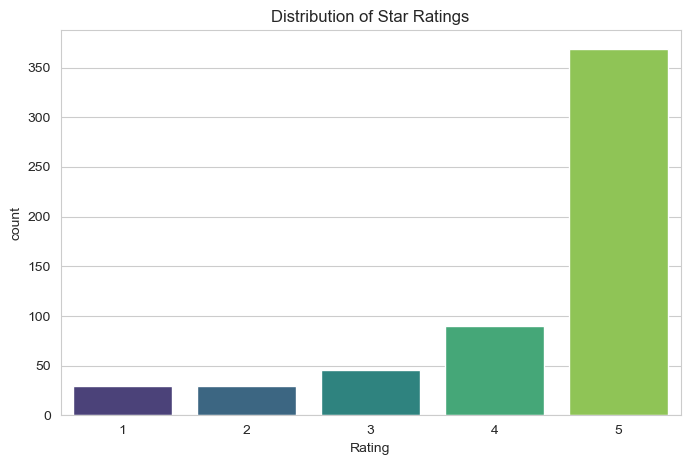

In [4]:
# Visualize the distribution of Ratings
plt.figure(figsize=(8, 5))
sns.countplot(x='Rating', data=df, palette='viridis')
plt.title('Distribution of Star Ratings')
plt.show()

## 2. Preprocessing
We'll perform basic cleaning: lowercasing and removing special characters.


In [5]:
# Basic cleaning function
import re

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text) # Remove punctuation
    return text

# Apply cleaning
df['Clean_Text'] = df['Text'].apply(clean_text)
df[['Text', 'Clean_Text']].head()

,Text,Clean_Text
0,Popchips are the bomb!! I use the parmesan ga...,popchips are the bomb i use the parmesan garl...
1,I like the puffed nature of this chip that mak...,i like the puffed nature of this chip that mak...
2,I just love these chips! I was always a big f...,i just love these chips i was always a big fa...
3,"These tasted like potatoe stix, that we got in...",these tasted like potatoe stix that we got in ...
4,These chips are great! They look almost like ...,these chips are great they look almost like a...


## 3. Feature Extraction (TF-IDF)
Let's find the most characteristic words for **5-star** vs **1-star** reviews using TF-IDF.


In [6]:
# Helper function to get top keywords
def get_top_keywords(data, n=10):
    tfidf = TfidfVectorizer(stop_words='english')
    X = tfidf.fit_transform(data)
    feature_names = np.array(tfidf.get_feature_names_out())
    
    # Sum tfidf scores for each word
    scores = X.sum(axis=0).A1
    top_indices = scores.argsort()[::-1][:n]
    
    return dict(zip(feature_names[top_indices], scores[top_indices]))

# Top words in 5-Star Reviews
print("Top words in 5-Star Reviews:")
five_star_text = df[df['Rating'] == 5]['Clean_Text']
print(get_top_keywords(five_star_text))

print("\nTop words in 1-Star Reviews:")
one_star_text = df[df['Rating'] == 1]['Clean_Text']
print(get_top_keywords(one_star_text))

Top words in 5-Star Reviews:
{'chips': np.float64(29.340721367462894), 'great': np.float64(17.024617754123113), 'love': np.float64(16.00094041233108), 'like': np.float64(15.223344340151764), 'flavor': np.float64(14.698965596601425), 'taste': np.float64(13.923296579099455), 'popchips': np.float64(13.644312552429408), 'potato': np.float64(13.336334277864049), 'bag': np.float64(13.132529747843483), 'good': np.float64(13.031781495231154)}

Top words in 1-Star Reviews:
{'chips': np.float64(2.599239043638407), 'like': np.float64(1.971300874626244), 'taste': np.float64(1.7816008182105947), 'flavor': np.float64(1.651443077044148), 'popchips': np.float64(1.5727465774027096), 'salt': np.float64(1.4835512724980278), 'box': np.float64(1.390452432195184), 'really': np.float64(1.3225339262722071), 'pepper': np.float64(1.2532538160507019), 'vinegar': np.float64(1.223289436114945)}


## 4. Sentiment Analysis
We will compare two approaches:
1.  **VADER (Lexicon-based)**: Good for social media / quick analysis.
2.  **Transformers (Deep Learning)**: Context-aware, generally more accurate.


In [7]:
import nltk
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sid = SentimentIntensityAnalyzer()

# Test on a specific review
sample_review = df.iloc[0]['Text']
print(f"Review: {sample_review}")
print(f"VADER Score: {sid.polarity_scores(sample_review)}")

Review: Popchips are the bomb!!  I use the parmesan garlic to scoop up cottage cheese as a healthy alternative to chips and dip.  My healthy eating program is saved.
VADER Score: {'neg': 0.0, 'neu': 0.593, 'pos': 0.407, 'compound': 0.9244}


Correlation between Rating and VADER Score: 0.41


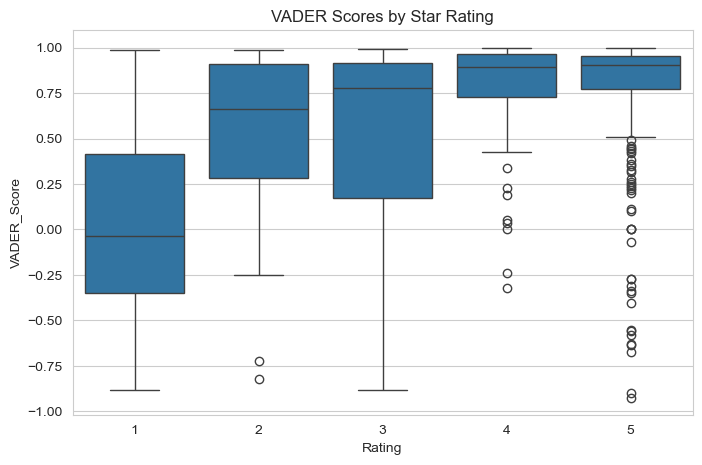

In [8]:
# Apply VADER to whole dataset
df['VADER_Score'] = df['Text'].apply(lambda x: sid.polarity_scores(str(x))['compound'])

# Check correlation with Rating
print(f"Correlation between Rating and VADER Score: {df['Rating'].corr(df['VADER_Score']):.2f}")

# Visualize
plt.figure(figsize=(8,5))
sns.boxplot(x='Rating', y='VADER_Score', data=df)
plt.title('VADER Scores by Star Rating')
plt.show()

### Transformer Pipeline
Now let's use a pre-trained model from Hugging Face.
We'll use a `sentiment-analysis` pipeline.


In [9]:
# Initialize Pipeline
# We'll use a specific model good for product reviews if possible, or the default
sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

# Test on the same sample
print(f"Review: {sample_review}")
print(f"Transformer Support: {sentiment_pipeline(sample_review)}")

Device set to use mps:0


Review: Popchips are the bomb!!  I use the parmesan garlic to scoop up cottage cheese as a healthy alternative to chips and dip.  My healthy eating program is saved.


Transformer Support: [{'label': 'POSITIVE', 'score': 0.9935213923454285}]


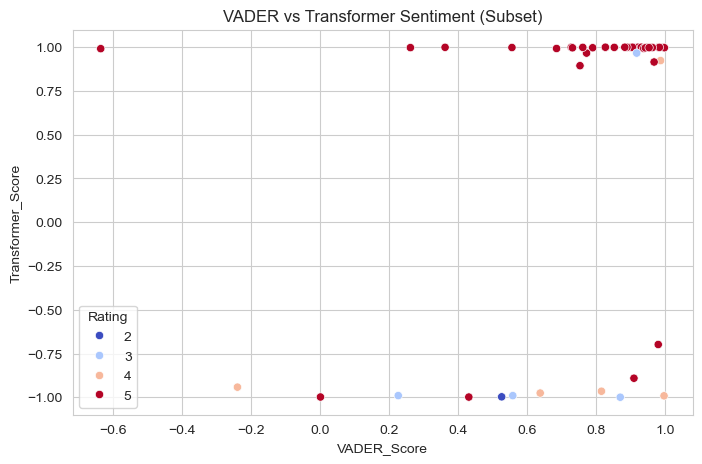

In [10]:
# Apply to first 50 reviews (to save time)
subset = df.head(50).copy()

def get_transformer_score(text):
    # Truncate to 512 tokens to avoid errors
    result = sentiment_pipeline(str(text)[:512])[0]
    score = result['score'] if result['label'] == 'POSITIVE' else -result['score']
    return score

subset['Transformer_Score'] = subset['Text'].apply(get_transformer_score)

# Plot correlation for subset
plt.figure(figsize=(8,5))
sns.scatterplot(x='VADER_Score', y='Transformer_Score', data=subset, hue='Rating', palette='coolwarm')
plt.title('VADER vs Transformer Sentiment (Subset)')
plt.show()

## 5. Named Entity Recognition (NER)
Let's see if we can identify specific flavors or organizations mentioned in the text using `spaCy`.


In [11]:
nlp = spacy.load("en_core_web_sm")

text_combined = " ".join(df['Text'].astype(str).tolist()[:1000]) # Sample text
doc = nlp(text_combined)

# Look for Entities
from collections import Counter

# Filter for ORG (Organizations) or PRODUCT
orgs = [ent.text for ent in doc.ents if ent.label_ in ['ORG', 'PRODUCT']]
print("Common Entities found:", Counter(orgs).most_common(10))

Common Entities found: [('Amazon', 79), ('BBQ', 76), ('PopChips', 18), ('Weight Watchers', 12), ('Costco', 11), ('Original', 9), ('WW', 6), ('Salt & Vinegar', 5), ('TOO', 4), ('Amazon.com', 4)]


## 6. Zero-Shot Classification
Finally, let's categorize the reviews into custom business categories without training a model.

Categories: `["Flavor", "Packaging", "Price", "Shipping", "Health"]`


In [12]:
classifier = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")

candidate_labels = ["Flavor", "Packaging", "Price", "Shipping", "Health"]

# Test on a few samples
sample_idx = [0, 5, 10] # Pick random indices

for idx in sample_idx:
    text = df.iloc[idx]['Text']
    result = classifier(text, candidate_labels)
    
    print("-" * 50)
    print(f"Review: {text[:100]}...") # Truncate for display
    print(f"Top Category: {result['labels'][0]} ({result['scores'][0]:.2f})")

Device set to use mps:0


--------------------------------------------------
Review: Popchips are the bomb!!  I use the parmesan garlic to scoop up cottage cheese as a healthy alternati...
Top Category: Flavor (0.41)


--------------------------------------------------
Review: The flavors of these are a bit on the strong side. Wish I hadn't bought so many...I thought I would ...
Top Category: Flavor (0.69)


--------------------------------------------------
Review: I love these chips. I am on the subscribe and save and get a case every two months, but have to orde...
Top Category: Shipping (0.33)


## Conclusion
We have successfully analyzed the Popchip reviews using various NLP techniques.
- **EDA** showed the distribution of ratings.
- **TF-IDF** highlighted key differentiating words.
- **Sentiment Analysis** allowed us to quantify the "positivity" of reviews.
- **NER** helped extract entities (though domain-specific training might be better for specific chip flavors).
- **Zero-Shot** provided instant categorization of reviews into topics.
